# Домашнее задание 3: мониторинг ВМ и Docker-образ для бэкенда

## Задание 1. Мониторинг ВМ

| № | Шаг | Требования |
|---|---|---|
| 1 | Node Exporter | запущен, `curl localhost:9100/metrics` отдаёт метрики `node_*` |

In [3]:
%%bash

curl -s http://localhost:9100/metrics | grep '^node_'

node_arp_entries{device="br-e5514e23e782"} 2
node_arp_entries{device="enp0s3"} 1
node_boot_time_seconds 1.792656684e+09
node_context_switches_total 7.929925e+06
node_cooling_device_cur_state{name="0",type="Processor"} 0
node_cooling_device_cur_state{name="1",type="Processor"} 0
node_cooling_device_max_state{name="0",type="Processor"} 0
node_cooling_device_max_state{name="1",type="Processor"} 0
node_cpu_guest_seconds_total{cpu="0",mode="nice"} 0
node_cpu_guest_seconds_total{cpu="0",mode="user"} 0
node_cpu_guest_seconds_total{cpu="1",mode="nice"} 0
node_cpu_guest_seconds_total{cpu="1",mode="user"} 0
node_cpu_seconds_total{cpu="0",mode="idle"} 1834.72
node_cpu_seconds_total{cpu="0",mode="iowait"} 23.57
node_cpu_seconds_total{cpu="0",mode="irq"} 0
node_cpu_seconds_total{cpu="0",mode="nice"} 1.47
node_cpu_seconds_total{cpu="0",mode="softirq"} 30.82
node_cpu_seconds_total{cpu="0",mode="steal"} 0
node_cpu_seconds_total{cpu="0",mode="system"} 186.39
node_cpu_seconds_total{cpu="0",mode="user"} 

| № | Шаг | Требования |
|---|---|---|
| 2 | Подключение к Prometheus | в `prometheus.yml` есть задание `job_name: node`, у цели понятная метка `instance` (`vm1`, …); на http://localhost:9090/targets цель в состоянии `UP` |

In [4]:
%%bash

curl -s http://localhost:9090/api/v1/targets \
  | jq '[.data.activeTargets[] | {
      job: .labels.job,
      instance: .labels.instance,
      health: .health,
      lastError: .lastError
    }]'

[
  {
    "job": "node",
    "instance": "vm1",
    "health": "up",
    "lastError": ""
  },
  {
    "job": "prometheus",
    "instance": "localhost:9090",
    "health": "up",
    "lastError": ""
  }
]


| № | Задание | Требования |
|---|---|---|
| 3 | Источник данных в Grafana | Prometheus добавлен в **Connections → Data sources**, **Save & test** проходит успешно |

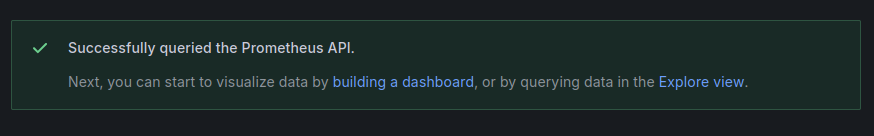

In [6]:
%%bash

curl -s -u admin:admin \
  http://localhost:3000/api/datasources/uid/fg1zbmvi8zgu8d/health | jq .

{
  "details": {
    "application": "Prometheus",
    "features": {
      "rulerApiEnabled": false
 

   }
  },
  "message": "Successfully queried the Prometheus API.",
  "status": "OK"
}


| № | Задание | Требования |
|---|---|---|
| 4 | Свой дашборд | Созданный самостоятельно, не импортированный: четыре панели — CPU, RAM, диск, сеть |